# 가스 불량 전체 사례와 정상의 차이

대회 범위의 가스 30행·30샷(CN7 13, RG3 17)을 모두 추출한다. 원본 `Reason`을 샷에 연결하고, CN7의 가스·미성형 동시 샷 2개를 별도로 표시한다.

비교: 제품별 전체 정상 → 같은 라벨 관측 구간 정상 → 같은 후보 run의 ±5·15·30분 정상. 마지막 비교는 **사후 설명용**이며 미래 정상·라벨을 사용하는 기준을 모델 피처로 사용하지 않는다. 이전 샷 피처는 실행된 03 노트북에서 생성한 과거값만 사용한다.

분석 범위는 CN7/RG3·S14·대회 제공 labeled 범위다. 다른 제품·설비가 포함된 전체 original/labeled_data.csv의 불량을 섞지 않는다. unlabeled를 정상이라고 가정하지 않는다. 성능 수치는 탐색 데이터의 분리도이며 검증 성능이 아니다.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import rankdata
from IPython.display import display
ROOT=Path.cwd()
if not (ROOT/'data').exists(): ROOT=ROOT.parent
TABLES=ROOT/'reports/tables'; FIGURES=ROOT/'reports/figures'
TABLES.mkdir(exist_ok=True,parents=True);FIGURES.mkdir(exist_ok=True,parents=True)
plt.rcParams.update({'font.family':['Malgun Gothic','DejaVu Sans'],'axes.unicode_minus':False,'figure.dpi':120})
raw=pd.read_csv(ROOT/'data/original/moldset_labeled.csv')
raw['TimeStamp']=pd.to_datetime(raw.TimeStamp)
raw['product']=raw.PART_NAME.str.extract(r'^(CN7|RG3)',expand=False)
raw['cavity']=raw.PART_NAME.str.extract(r'(LH|RH)\s*$',expand=False)
competition_indices=np.concatenate([pd.read_csv(ROOT/f'data/moldset_labeled_{p}.csv')['Unnamed: 0'].to_numpy() for p in ['cn7','rg3']])
raw=raw.loc[raw['Unnamed: 0'].isin(competition_indices)].copy()
shots=pd.read_csv(TABLES/'run_shot_feature_candidates.csv',parse_dates=['TimeStamp'])
shots=shots.sort_values(['product','TimeStamp']).reset_index(drop=True).copy()
keys=['EQUIP_CD','TimeStamp','product']
assert not shots.duplicated(keys).any()
features=pd.read_csv(ROOT/'data/moldset_labeled_cn7.csv',nrows=0).columns.drop(['Unnamed: 0','PassOrFail']).tolist()
check=raw.groupby(keys)[features].first().reset_index().merge(shots[keys+features],on=keys,suffixes=('_raw','_shot'))
assert len(check)==1197
for f in features:
    np.testing.assert_allclose(check[f+'_raw'],check[f+'_shot'],atol=1e-5)
gap=shots.groupby('product').TimeStamp.diff().dt.total_seconds()
shots['label_block']=(shots['product'].ne(shots['product'].shift())|gap.isna()|gap.gt(1800)).cumsum()
shots['gas_flag']=shots.Reason.str.contains('가스',regex=False)
shots['mixed_shortshot']=shots.Reason.str.contains('미성형',regex=False)&shots.gas_flag
gas_rows=raw.loc[raw.Reason.eq('가스')].sort_values(['product','TimeStamp'])
gas_rows.to_csv(TABLES/'gas_all_original_rows.csv',index=False,encoding='utf-8-sig')
cavities=gas_rows.groupby(keys).cavity.agg(lambda s:'|'.join(sorted(set(s)))).rename('gas_cavity')
shots=shots.merge(cavities,on=keys,how='left')
gas=shots.loc[shots.gas_flag].copy()
assert len(gas_rows)==30 and len(gas)==30
assert gas.groupby('product').size().to_dict()=={'CN7':13,'RG3':17}
assert gas.mixed_shortshot.sum()==2
gas['gas_gap_sec']=gas.groupby('product').TimeStamp.diff().dt.total_seconds()
gas['gas_event_id']=(gas['product'].ne(gas['product'].shift())|gas.gas_gap_sec.isna()|gas.gas_gap_sec.gt(120)|gas.run_id.ne(gas.run_id.shift())).cumsum()
gas.to_csv(TABLES/'gas_all_shots.csv',index=False,encoding='utf-8-sig')
events=gas.groupby(['product','gas_event_id']).agg(start=('TimeStamp','min'),end=('TimeStamp','max'),gas_shots=('TimeStamp','size'),mixed=('mixed_shortshot','sum'))
events.to_csv(TABLES/'gas_temporal_events.csv',encoding='utf-8-sig')
display(gas[['product','TimeStamp','gas_cavity','Reason','run_id']])
display(events)
print('Gas rows/shots:',len(gas_rows),len(gas),'Mixed gas+short-shot:',gas.mixed_shortshot.sum())


,product,TimeStamp,gas_cavity,Reason,run_id
24,CN7,2020-10-16 05:21:38,LH,가스,20201016_035120_CN7
40,CN7,2020-10-16 05:37:29,RH,가스,20201016_035120_CN7
48,CN7,2020-10-16 05:45:26,RH,가스,20201016_035120_CN7
50,CN7,2020-10-16 05:47:24,RH,가스,20201016_035120_CN7
51,CN7,2020-10-16 05:48:24,RH,가스,20201016_035120_CN7
52,CN7,2020-10-16 05:49:24,RH,가스,20201016_035120_CN7
53,CN7,2020-10-16 05:50:25,RH,가스,20201016_035120_CN7
54,CN7,2020-10-16 05:51:23,RH,가스,20201016_035120_CN7
55,CN7,2020-10-16 05:52:23,RH,가스,20201016_035120_CN7
56,CN7,2020-10-16 05:53:23,RH,가스,20201016_035120_CN7


start                 end  gas_shots  mixed
product gas_event_id                                                          
CN7     1            2020-10-16 05:21:38 2020-10-16 05:21:38          1      0
        2            2020-10-16 05:37:29 2020-10-16 05:37:29          1      0
        3            2020-10-16 05:45:26 2020-10-16 05:54:21          9      0
        4            2020-10-16 05:56:22 2020-10-16 05:57:20          2      2
RG3     5            2020-10-22 00:51:52 2020-10-22 00:51:52          1      0
        6            2020-10-22 01:04:15 2020-10-22 01:04:15          1      0
        7            2020-10-22 01:26:54 2020-10-22 01:26:54          1      0
        8            2020-10-22 01:57:47 2020-10-22 01:57:47          1      0
        9            2020-10-22 04:46:36 2020-10-22 04:46:36          1      0
        10           2020-10-22 04:51:46 2020-10-22 04:51:46          1      0
        11           2020-10-22 04:57:56 2020-10-22 04:57:56          1      0
        12           2020-10-22 05:10:17 2020-10-22 05:10:17          1      0
        13           2020-10-22 05:44:15 2020-10-22 05:44:15          1      0
        14           2020-10-22 07:37:31 2020-10-22 07:37:31          1      0
        15           2020-10-23 01:03:33 2020-10-23 01:03:33          1      0
        16           2020-10-23 01:24:09 2020-10-23 01:24:09          1      0
        17           2020-10-23 02:01:11 2020-10-23 02:01:11          1      0
        18           2020-10-23 05:15:46 2020-10-23 05:15:46          1      0
        19           2020-10-23 05:59:00 2020-10-23 05:59:00          1      0
        20           2020-10-23 07:15:11 2020-10-23 07:15:11          1      0
        21           2020-10-23 07:21:20 2020-10-23 07:21:20          1      0

Gas rows/shots: 30 30 Mixed gas+short-shot: 2


In [2]:
# Named sensor semantics anomalies remain unconfirmed, so max-average differences are not interpreted physically.
candidate_features=[f for f in features if shots[f].nunique()>1]
candidate_features += [c for c in shots.columns if c.endswith(('__delta1','__dev10','__past10_std')) and shots[c].nunique()>1]
candidate_features += ['mold_delta','pressure_delta','injection_minus_filling']
def auc_high(y,x):
    y=np.asarray(y,dtype=int);x=np.asarray(x,dtype=float)
    n1,n0=y.sum(),(1-y).sum()
    if not n1 or not n0: return np.nan
    return float((rankdata(x)[y==1].sum()-n1*(n1+1)/2)/(n1*n0))
summaries,block_stats=[],[]
for product,pg in shots.groupby('product'):
    for mode in ['all_gas','pure_gas']:
        target=pg.loc[pg.gas_flag & (~pg.mixed_shortshot if mode=='pure_gas' else True)]
        normal=pg.loc[pg.PassOrFail.eq(0)]
        # Exclude short-shot-only shots from both groups.
        for f in candidate_features:
            t=target[f].dropna();n=normal[f].dropna()
            if not len(t) or not len(n): continue
            a=auc_high(np.r_[np.ones(len(t)),np.zeros(len(n))],np.r_[t,n])
            block_auc,weights,delta,block_direction=[],[],[],[]
            for bid,tg in target.groupby('label_block'):
                ng=normal.loc[normal.label_block.eq(bid)]
                tv,nv=tg[f].dropna(),ng[f].dropna()
                if not len(tv) or not len(nv):continue
                ba=auc_high(np.r_[np.ones(len(tv)),np.zeros(len(nv))],np.r_[tv,nv])
                diff=tv.mean()-nv.mean()
                block_auc.append(ba);weights.append(len(tv));delta.append(diff)
                block_direction.append(np.sign(diff))
                block_stats.append({'product':product,'mode':mode,'label_block':bid,'feature':f,
                                    'gas_n':len(tv),'normal_n':len(nv),'gas_mean':tv.mean(),'normal_mean':nv.mean(),
                                    'gas_median':tv.median(),'normal_median':nv.median(),'delta_mean':diff,'auc_high':ba})
            weighted_auc=np.average(block_auc,weights=weights) if weights else np.nan
            summaries.append({'product':product,'mode':mode,'feature':f,'gas_n':len(t),'normal_n':len(n),
                              'gas_median':t.median(),'normal_median':n.median(),
                              'global_mean_difference':t.mean()-n.mean(),'global_auc_high':a,
                              'block_mean_difference':np.average(delta,weights=weights) if weights else np.nan,
                              'block_auc_high':weighted_auc,'block_direction_auc':max(weighted_auc,1-weighted_auc),
                              'blocks':len(weights),'positive_blocks':sum(d>0 for d in delta)})
comparison=pd.DataFrame(summaries)
block_details=pd.DataFrame(block_stats)
comparison.to_csv(TABLES/'gas_normal_feature_comparison.csv',index=False)
block_details.to_csv(TABLES/'gas_normal_by_observation_block.csv',index=False)
for p in ['CN7','RG3']:
    print(p,'pure gas, same observation block: exploratory separation only')
    display(comparison.loc[comparison['product'].eq(p)&comparison['mode'].eq('pure_gas')].sort_values('block_direction_auc',ascending=False).head(15))


CN7 pure gas, same observation block: exploratory separation only


,product,mode,feature,gas_n,normal_n,gas_median,normal_median,global_mean_difference,global_auc_high,block_mean_difference,block_auc_high,block_direction_auc,blocks,positive_blocks
173,CN7,pure_gas,Barrel_Temperature_2__past10_std,11,592,0.523341,3.299848e-01,0.143037,0.861640,0.161770,0.877220,0.877220,1,1
103,CN7,pure_gas,Clamp_Close_Time,11,592,7.130000,7.120000e+00,0.007173,0.808738,0.007680,0.826541,0.826541,1,1
131,CN7,pure_gas,Plasticizing_Time__past10_std,11,592,0.014758,1.837915e-02,-0.004239,0.302979,-0.004809,0.198537,0.801463,1,0
161,CN7,pure_gas,Max_Switch_Over_Pressure__past10_std,11,592,0.202485,2.573359e-01,-0.035853,0.279330,-0.055482,0.199060,0.800940,1,0
188,CN7,pure_gas,Hopper_Temperature__past10_std,11,592,0.598516,4.791776e-01,0.133084,0.798449,0.153898,0.793887,0.793887,1,1
155,CN7,pure_gas,Average_Screw_RPM__past10_std,11,592,0.031625,4.216628e-02,-0.000011,0.342905,-0.008500,0.235632,0.764368,1,0
143,CN7,pure_gas,Plasticizing_Position__past10_std,11,592,0.006323,9.485464e-03,-0.002611,0.153332,-0.001494,0.242163,0.757837,1,0
137,CN7,pure_gas,Clamp_Close_Time__past10_std,11,592,0.004216,2.398080e-09,0.003253,0.875921,0.002499,0.757053,0.757053,1,1
179,CN7,pure_gas,Barrel_Temperature_4__past10_std,11,592,0.690889,8.059832e-01,-0.083186,0.305206,-0.113238,0.245820,0.754180,1,0
158,CN7,pure_gas,Max_Injection_Pressure__past10_std,11,592,0.052708,6.749571e-02,-0.006517,0.438729,-0.020122,0.289446,0.710554,1,0


RG3 pure gas, same observation block: exploratory separation only


,product,mode,feature,gas_n,normal_n,gas_median,normal_median,global_mean_difference,global_auc_high,block_mean_difference,block_auc_high,block_direction_auc,blocks,positive_blocks
338,RG3,pure_gas,Cushion_Position__past10_std,16,562,0.009725,0.008507,0.001717,0.666092,0.001845,0.693145,0.693145,4,4
371,RG3,pure_gas,Barrel_Temperature_2__past10_std,16,562,0.370055,0.404489,-0.045202,0.300934,-0.040393,0.313960,0.686040,4,1
374,RG3,pure_gas,Barrel_Temperature_3__past10_std,16,562,0.293106,0.332999,-0.035403,0.343416,-0.038289,0.348877,0.651123,4,1
356,RG3,pure_gas,Max_Injection_Pressure__past10_std,16,562,0.131207,0.122930,0.007743,0.617660,0.007446,0.628298,0.628298,4,4
379,RG3,pure_gas,Barrel_Temperature_5__dev10,16,562,0.125008,0.000000,0.132406,0.631172,0.132036,0.623451,0.623451,4,3
320,RG3,pure_gas,Mold_Temperature_4,17,566,23.500000,23.799999,-0.136531,0.437747,-0.084107,0.377957,0.622043,4,1
380,RG3,pure_gas,Barrel_Temperature_5__past10_std,16,562,0.346361,0.293642,0.031944,0.637789,0.029538,0.619310,0.619310,4,1
316,RG3,pure_gas,Barrel_Temperature_5,17,566,265.100006,265.000000,0.114113,0.615309,0.112380,0.618318,0.618318,4,3
383,RG3,pure_gas,Barrel_Temperature_6__past10_std,16,562,0.177327,0.196921,-0.015427,0.389958,-0.013403,0.386459,0.613541,4,0
387,RG3,pure_gas,Mold_Temperature_3__delta1,17,565,0.000000,0.000000,0.038345,0.610984,0.038200,0.613018,0.613018,4,3


In [3]:
# For every gas case, compare the same-run labeled normal neighbors, including future neighbors for retrospective EDA only.
details=[]
for row in gas.itertuples():
    base=shots.loc[shots['product'].eq(row.product)&shots.run_id.eq(row.run_id)&shots.PassOrFail.eq(0)]
    for window in [5,15,30]:
        neighbors=base.loc[(base.TimeStamp-row.TimeStamp).dt.total_seconds().abs().le(window*60)]
        for f in candidate_features:
            v=neighbors[f].dropna()
            x=getattr(row,f)
            med=v.median() if len(v) else np.nan
            details.append({'product':row.product,'TimeStamp':row.TimeStamp,'gas_event_id':row.gas_event_id,
                            'mixed_shortshot':row.mixed_shortshot,'window_minutes':window,'feature':f,
                            'gas_value':x,'normal_median':med,'difference':x-med,'normal_n':len(v)})
local=pd.DataFrame(details)
local.to_csv(TABLES/'gas_case_local_normal_differences.csv',index=False,encoding='utf-8-sig')
local_summaries=[]
for (p,mode,w,f),g in pd.concat([
    local.assign(mode='all_gas'),
    local.loc[~local.mixed_shortshot].assign(mode='pure_gas')]).groupby(['product','mode','window_minutes','feature']):
    valid=g.loc[g.normal_n.ge(3)&g.difference.notna()]
    if not len(valid):continue
    # Treat differences below numerical float precision as ties.
    d=valid.difference.where(valid.difference.abs().gt(1e-5),0)
    event_medians=valid.assign(diff=d).groupby('gas_event_id')['diff'].median()
    local_summaries.append({'product':p,'mode':mode,'window_minutes':w,'feature':f,
                           'gas_cases':len(valid),'median_difference':d.median(),'mean_difference':d.mean(),
                           'positive_cases':int(d.gt(0).sum()),'negative_cases':int(d.lt(0).sum()),'tie_cases':int(d.eq(0).sum()),
                           'direction_agreement':max(d.gt(0).mean(),d.lt(0).mean()),
                           'independent_event_proxy_count':len(event_medians),
                           'median_event_difference':event_medians.median()})
local_summary=pd.DataFrame(local_summaries)
local_summary.to_csv(TABLES/'gas_local_normal_difference_summary.csv',index=False)
for p in ['CN7','RG3']:
    print(p,'pure gas, +/-15min controls')
    display(local_summary.loc[local_summary['product'].eq(p)&local_summary['mode'].eq('pure_gas')&
                               local_summary.window_minutes.eq(15)].sort_values('direction_agreement',ascending=False).head(15))


CN7 pure gas, +/-15min controls


,product,mode,window_minutes,feature,gas_cases,median_difference,mean_difference,positive_cases,negative_cases,tie_cases,direction_agreement,independent_event_proxy_count,median_event_difference
419,CN7,pure_gas,15,Barrel_Temperature_4__past10_std,11,-0.036432,-0.049797,1,10,0,0.909091,3,-0.027759
411,CN7,pure_gas,15,Barrel_Temperature_2__past10_std,11,0.226169,0.177731,10,1,0,0.909091,3,0.056052
403,CN7,pure_gas,15,Average_Screw_RPM__past10_std,11,-0.010542,-0.010227,1,10,0,0.909091,3,-0.003335
467,CN7,pure_gas,15,Max_Injection_Speed__past10_std,11,-0.051532,-0.544013,1,10,0,0.909091,3,-0.012603
475,CN7,pure_gas,15,Max_Switch_Over_Pressure__past10_std,11,-0.068319,-0.054591,1,10,0,0.909091,3,-0.014693
489,CN7,pure_gas,15,Plasticizing_Time__delta1,11,0.010000,0.012273,10,1,0,0.909091,3,0.010000
491,CN7,pure_gas,15,Plasticizing_Time__past10_std,11,-0.007332,-0.005794,1,10,0,0.909091,3,-0.007332
447,CN7,pure_gas,15,Filling_Time__past10_std,11,-0.003190,-0.012107,1,10,0,0.909091,3,-0.000861
459,CN7,pure_gas,15,Max_Back_Pressure__past10_std,11,-0.062330,-0.071188,1,10,0,0.909091,3,-0.023913
399,CN7,pure_gas,15,Average_Back_Pressure__past10_std,11,-0.050245,-0.037748,2,9,0,0.818182,3,0.001480


RG3 pure gas, +/-15min controls


,product,mode,window_minutes,feature,gas_cases,median_difference,mean_difference,positive_cases,negative_cases,tie_cases,direction_agreement,independent_event_proxy_count,median_event_difference
1005,RG3,pure_gas,15,Barrel_Temperature_2__past10_std,16,-0.030952,-0.027548,2,14,0,0.875000,16,-0.030952
1009,RG3,pure_gas,15,Barrel_Temperature_3__past10_std,16,-0.047927,-0.046839,3,13,0,0.812500,16,-0.047927
1014,RG3,pure_gas,15,Barrel_Temperature_5,17,0.100006,0.138237,12,5,0,0.705882,17,0.100006
1057,RG3,pure_gas,15,Max_Injection_Pressure__past10_std,16,0.006472,0.008290,11,3,2,0.687500,16,0.006472
1069,RG3,pure_gas,15,Max_Switch_Over_Pressure__past10_std,16,0.009082,0.002209,11,5,0,0.687500,16,0.009082
1043,RG3,pure_gas,15,Hopper_Temperature__delta1,17,-0.099998,0.023529,6,11,0,0.647059,17,-0.099998
1051,RG3,pure_gas,15,Max_Back_Pressure__delta1,17,0.100002,0.058824,11,6,0,0.647059,17,0.100002
1017,RG3,pure_gas,15,Barrel_Temperature_5__past10_std,16,0.012101,0.016146,10,6,0,0.625000,16,0.012101
1016,RG3,pure_gas,15,Barrel_Temperature_5__dev10,16,0.150009,0.151563,10,6,0,0.625000,16,0.150009
992,RG3,pure_gas,15,Average_Back_Pressure__dev10,16,0.087499,0.079687,10,6,0,0.625000,16,0.087499


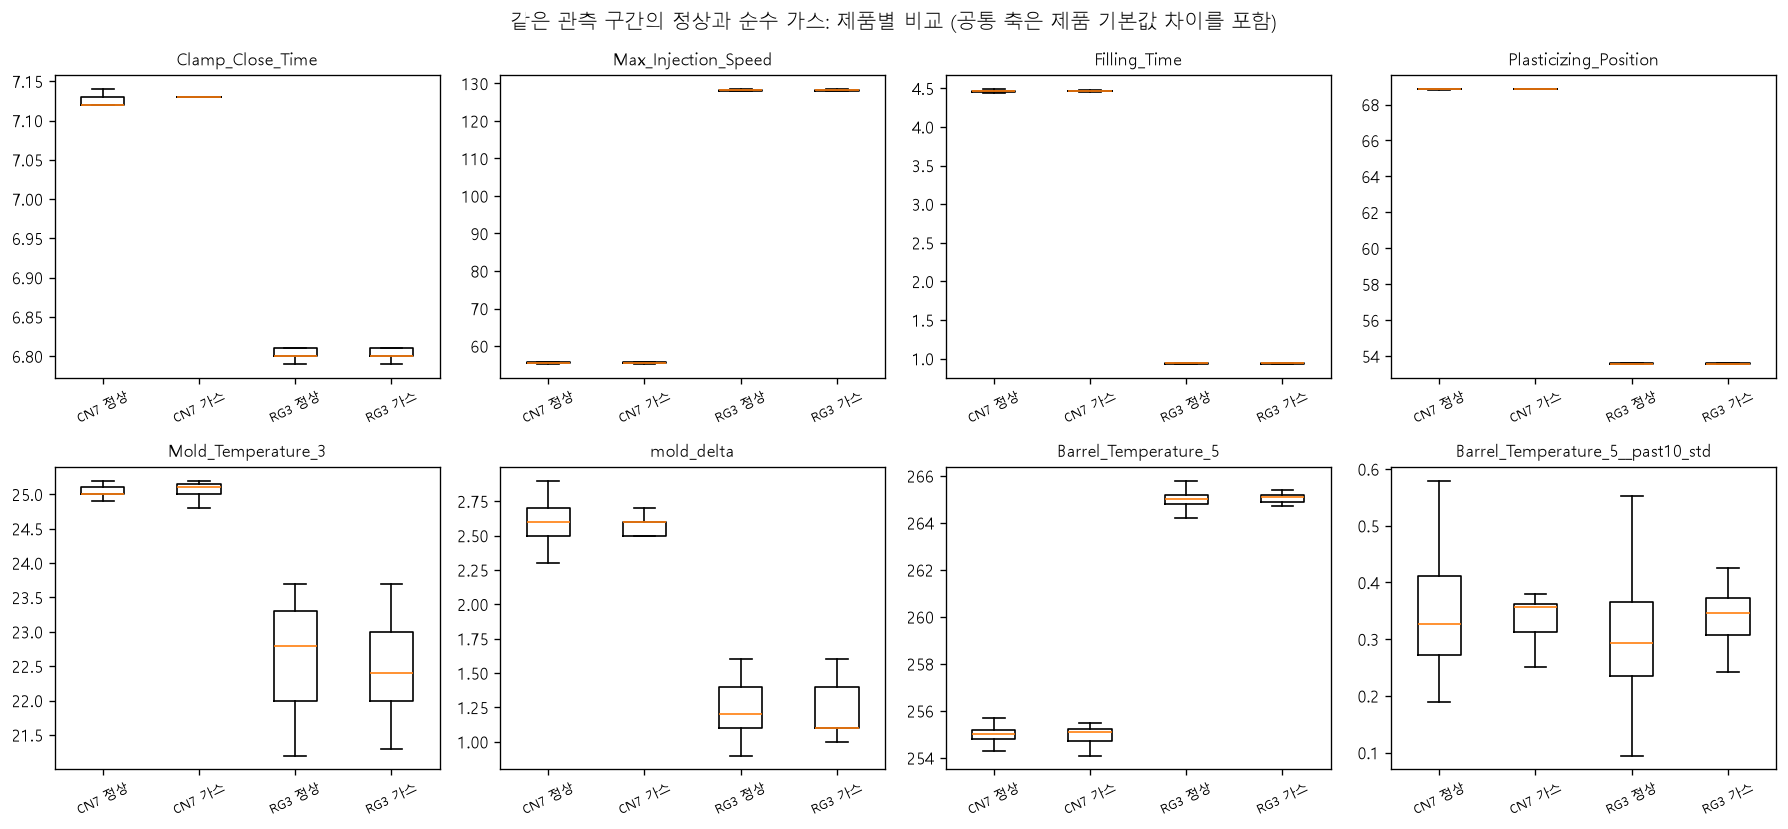

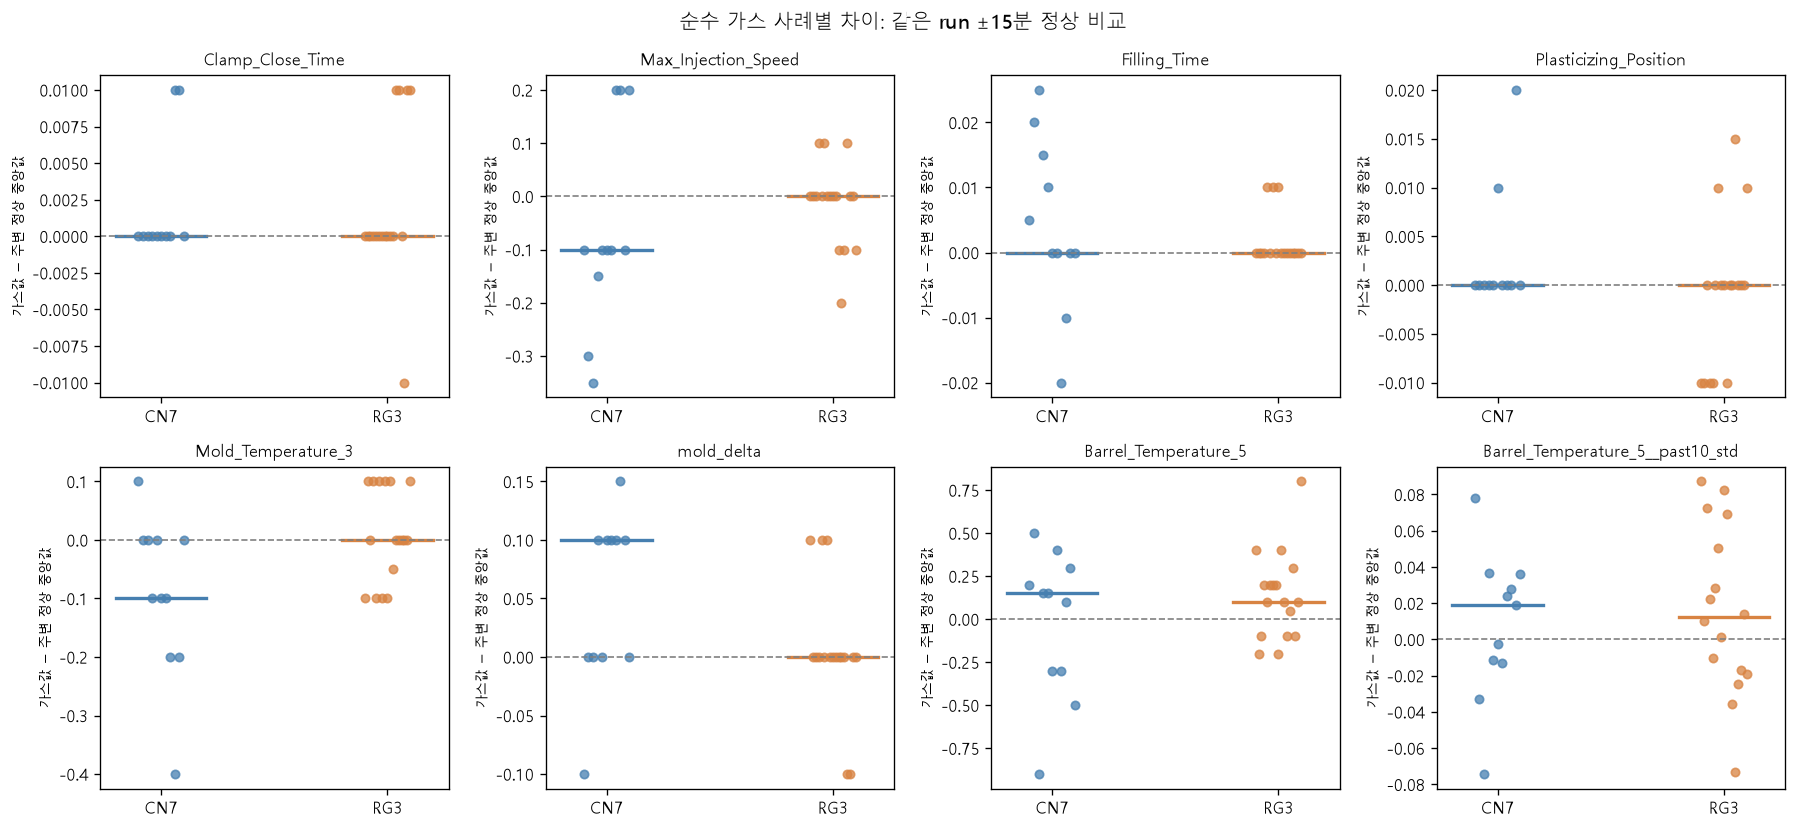

Verified all 30 gas cases, original/shot consistency, mixed-shot flagging and control coverage.


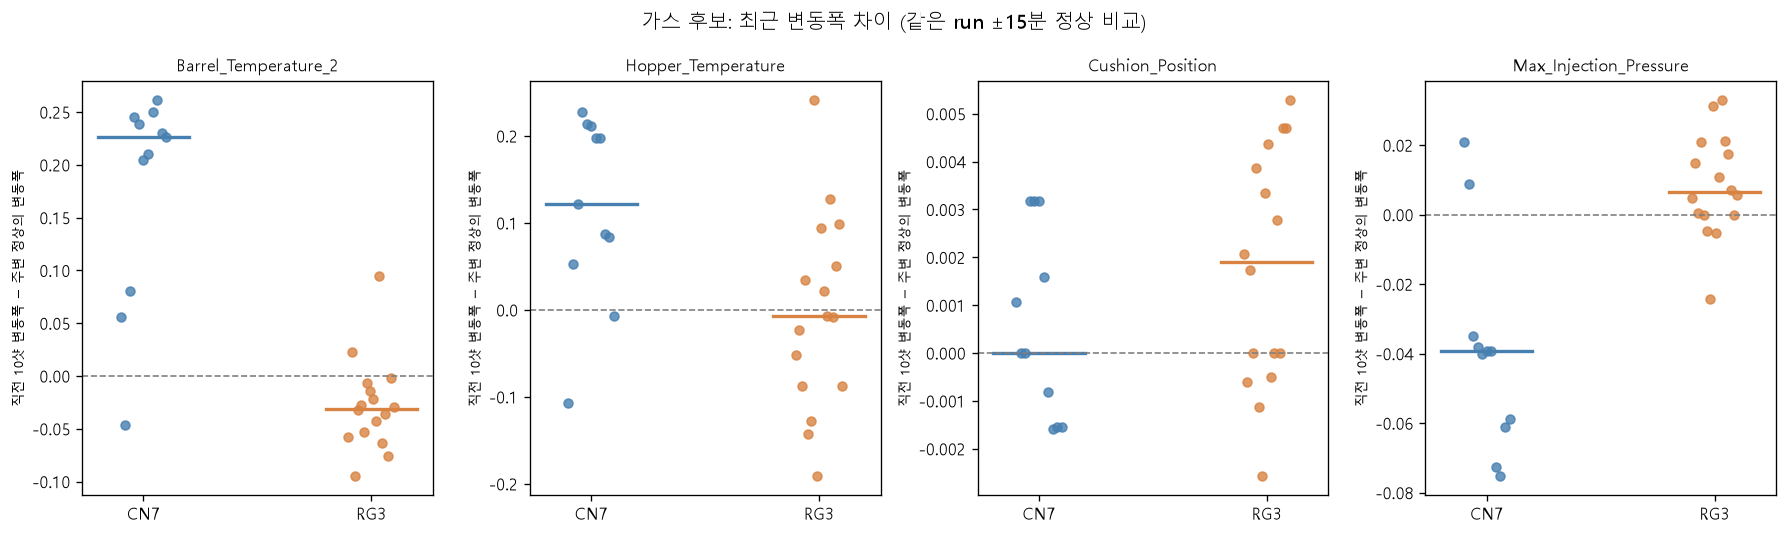

In [4]:
# Build a concise casebook: key raw values and each case's +/-15min normal baseline.
brief_features=['Clamp_Close_Time','Max_Injection_Speed','Filling_Time','Plasticizing_Position',
                'Max_Back_Pressure','Barrel_Temperature_5','Mold_Temperature_3','Mold_Temperature_4',
                'mold_delta','Barrel_Temperature_5__past10_std','Mold_Temperature_3__dev10']
casebook=gas[['product','TimeStamp','gas_cavity','Reason','run_id','gas_event_id','mixed_shortshot']].copy()
for f in brief_features:
    target=local.loc[local.window_minutes.eq(15)&local.feature.eq(f)][
        ['product','TimeStamp','gas_value','normal_median','difference','normal_n']]
    target=target.rename(columns={'gas_value':f,'normal_median':f+'__nearby_normal_median',
                                  'difference':f+'__nearby_difference','normal_n':f+'__nearby_normal_n'})
    casebook=casebook.merge(target,on=['product','TimeStamp'],how='left')
casebook.to_csv(TABLES/'gas_casebook_with_normal_baselines.csv',index=False,encoding='utf-8-sig')
# Plot raw comparisons in same observation blocks, explicitly separate mixed shots.
show_features=['Clamp_Close_Time','Max_Injection_Speed','Filling_Time','Plasticizing_Position',
               'Mold_Temperature_3','mold_delta','Barrel_Temperature_5','Barrel_Temperature_5__past10_std']
fig,axs=plt.subplots(2,4,figsize=(15,7))
for ax,f in zip(axs.flat,show_features):
    values=[];labels=[]
    for p in ['CN7','RG3']:
        pg=shots.loc[shots['product'].eq(p)]
        valid_blocks=pg.loc[pg.gas_flag,'label_block'].unique()
        normal=pg.loc[pg.PassOrFail.eq(0)&pg.label_block.isin(valid_blocks),f].dropna()
        pure=pg.loc[pg.gas_flag&~pg.mixed_shortshot,f].dropna()
        values.extend([normal,pure]);labels.extend([p+' 정상',p+' 가스'])
    ax.boxplot(values,tick_labels=labels,showfliers=False)
    ax.set_title(f,fontsize=10);ax.tick_params(axis='x',rotation=25,labelsize=8)
fig.suptitle('같은 관측 구간의 정상과 순수 가스: 제품별 비교 (공통 축은 제품 기본값 차이를 포함)')
fig.tight_layout()
fig.savefig(FIGURES/'gas_normal_raw_comparison.png',bbox_inches='tight')
plt.show()
# Local contrast distributions use own units; products shown separately.
fig,axs=plt.subplots(2,4,figsize=(15,7))
for ax,f in zip(axs.flat,show_features):
    for xpos,p,color in [(0,'CN7','#467fb0'),(1,'RG3','#d88342')]:
        gg=local.loc[local['product'].eq(p)&~local.mixed_shortshot&local.window_minutes.eq(15)&local.feature.eq(f)&local.normal_n.ge(3)]
        offsets=np.linspace(-.1,.1,len(gg)) if len(gg) else []
        ax.scatter(xpos+offsets,gg.difference,s=25,color=color,alpha=.75)
        if len(gg):ax.plot([xpos-.2,xpos+.2],[gg.difference.median()]*2,color=color,linewidth=2)
    ax.axhline(0,color='gray',linestyle='--',linewidth=1)
    ax.set_xticks([0,1],['CN7','RG3']);ax.set_title(f,fontsize=10);ax.set_ylabel('가스값 − 주변 정상 중앙값',fontsize=8)
fig.suptitle('순수 가스 사례별 차이: 같은 run ±15분 정상 비교')
fig.tight_layout()
fig.savefig(FIGURES/'gas_local_normal_differences.png',bbox_inches='tight')
plt.show()
# Source extraction and casebook checks.
assert len(casebook)==30 and not casebook.duplicated(['product','TimeStamp']).any()
assert local.groupby(['window_minutes','feature']).size().eq(30).all()
assert set(gas_rows['TimeStamp'])==set(gas['TimeStamp'])
print('Verified all 30 gas cases, original/shot consistency, mixed-shot flagging and control coverage.')
# 변동폭 후보: 각 점은 순수 가스 한 샷의 주변 정상 대비 차이.
var_features=['Barrel_Temperature_2__past10_std','Hopper_Temperature__past10_std',
              'Cushion_Position__past10_std','Max_Injection_Pressure__past10_std']
fig,axs=plt.subplots(1,4,figsize=(15,4.5))
for ax,f in zip(axs,var_features):
    for xpos,p,color in [(0,'CN7','#467fb0'),(1,'RG3','#d88342')]:
        gg=local.loc[local['product'].eq(p)&~local.mixed_shortshot&local.window_minutes.eq(15)&local.feature.eq(f)&local.normal_n.ge(3)].dropna(subset=['difference'])
        ax.scatter(xpos+np.linspace(-.1,.1,len(gg)),gg.difference,color=color,s=28,alpha=.8)
        if len(gg): ax.plot([xpos-.2,xpos+.2],[gg.difference.median()]*2,color=color,linewidth=2)
    ax.axhline(0,color='gray',linestyle='--',linewidth=1)
    ax.set_xticks([0,1],['CN7','RG3']);ax.set_title(f.replace('__past10_std',''),fontsize=10)
    ax.set_ylabel('직전 10샷 변동폭 − 주변 정상의 변동폭',fontsize=8)
fig.suptitle('가스 후보: 최근 변동폭 차이 (같은 run ±15분 정상 비교)')
fig.tight_layout()
fig.savefig(FIGURES/'gas_variability_candidates.png',bbox_inches='tight')
plt.show()
